In [1]:
import pandas as pd # For working with CSV file
import numpy as np # For working with arrays

In [2]:
df = pd.read_csv("data/US_Accidents_March23_sampled_500k.csv")
df

,ID,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),...,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight
0,A-2047758,Source2,2,2019-06-12 10:10:56,2019-06-12 10:55:58,30.641211,-91.153481,NaN,NaN,0.000,...,False,False,False,False,True,False,Day,Day,Day,Day
1,A-4694324,Source1,2,2022-12-03 23:37:14.000000000,2022-12-04 01:56:53.000000000,38.990562,-77.399070,38.990037,-77.398282,0.056,...,False,False,False,False,False,False,Night,Night,Night,Night
2,A-5006183,Source1,2,2022-08-20 13:13:00.000000000,2022-08-20 15:22:45.000000000,34.661189,-120.492822,34.661189,-120.492442,0.022,...,False,False,False,False,True,False,Day,Day,Day,Day
3,A-4237356,Source1,2,2022-02-21 17:43:04,2022-02-21 19:43:23,43.680592,-92.993317,43.680574,-92.972223,1.054,...,False,False,False,False,False,False,Day,Day,Day,Day
4,A-6690583,Source1,2,2020-12-04 01:46:00,2020-12-04 04:13:09,35.395484,-118.985176,35.395476,-118.985995,0.046,...,False,False,False,False,False,False,Night,Night,Night,Night
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
499995,A-6077227,Source1,2,2021-12-15 07:30:00,2021-12-15 07:50:30,45.522510,-123.084104,45.520225,-123.084211,0.158,...,False,False,False,False,False,False,Night,Day,Day,Day
499996,A-6323243,Source1,2,2021-12-19 16:25:00,2021-12-19 17:40:37,26.702570,-80.111169,26.703141,-80.111133,0.040,...,False,False,False,False,False,False,Day,Day,Day,Day
499997,A-3789256,Source1,2,2022-04-13 19:28:29,2022-04-13 21:33:44,34.561862,-112.259620,34.566822,-112.267150,0.549,...,False,False,False,False,True,False,Night,Night,Day,Day
499998,A-7030381,Source1,3,2020-05-15 17:20:56,2020-05-15 17:50:56,38.406680,-78.619310,38.406680,-78.619310,0.000,...,False,False,False,False,True,False,Day,Day,Day,Day


# Preprocessing

In [3]:
# Number of observations
len(df)

500000

In [4]:
# Dataset dimensions: (rows, columns)
df.shape

(500000, 46)

In [5]:
# Column names, non-null counts, and memory usage
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 46 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   ID                     500000 non-null  object 
 1   Source                 500000 non-null  object 
 2   Severity               500000 non-null  int64  
 3   Start_Time             500000 non-null  object 
 4   End_Time               500000 non-null  object 
 5   Start_Lat              500000 non-null  float64
 6   Start_Lng              500000 non-null  float64
 7   End_Lat                279623 non-null  float64
 8   End_Lng                279623 non-null  float64
 9   Distance(mi)           500000 non-null  float64
 10  Description            499999 non-null  object 
 11  Street                 499309 non-null  object 
 12  City                   499981 non-null  object 
 13  County                 500000 non-null  object 
 14  State                  500000 non-nu

In [6]:
# Descriptive statistics for numeric and categorical columns
df.describe()

,Severity,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),Precipitation(in)
count,500000.000000,500000.000000,500000.000000,279623.000000,279623.000000,500000.000000,489534.000000,370983.000000,488870.000000,491072.000000,488709.000000,463013.000000,357384.000000
mean,2.212748,36.206421,-94.736583,36.273192,-95.776553,0.564317,61.646254,58.229028,64.834921,29.536621,9.091540,7.681347,0.008289
std,0.486661,5.071411,17.405761,5.265333,18.120211,1.774872,19.000133,22.352246,22.826158,1.008666,2.708083,5.431361,0.101865
min,1.000000,24.562117,-124.497420,24.570110,-124.497419,0.000000,-77.800000,-53.200000,1.000000,0.120000,0.000000,0.000000,0.000000
25%,2.000000,33.416823,-117.233047,33.474773,-117.778324,0.000000,49.000000,43.000000,48.000000,29.370000,10.000000,4.600000,0.000000
50%,2.000000,35.832147,-87.794365,36.192669,-88.039013,0.029000,64.000000,62.000000,67.000000,29.860000,10.000000,7.000000,0.000000
75%,2.000000,40.082443,-80.359601,40.181341,-80.252449,0.465000,76.000000,75.000000,84.000000,30.030000,10.000000,10.400000,0.000000
max,4.000000,48.999569,-67.484130,48.998901,-67.484130,193.479996,207.000000,207.000000,100.000000,38.440000,130.000000,822.800000,10.130000


In [7]:
# Data type of every column
df.dtypes.to_frame(name="data_type")

,data_type
ID,object
Source,object
Severity,int64
Start_Time,object
End_Time,object
Start_Lat,float64
Start_Lng,float64
End_Lat,float64
End_Lng,float64
Distance(mi),float64


In [8]:
# Missing-value count and percentage by column
print(df.isna().sum().sort_values(ascending=False))

End_Lng                  220377
End_Lat                  220377
Precipitation(in)        142616
Wind_Chill(F)            129017
Wind_Speed(mph)           36987
Visibility(mi)            11291
Wind_Direction            11197
Humidity(%)               11130
Weather_Condition         11101
Temperature(F)            10466
Pressure(in)               8928
Weather_Timestamp          7674
Sunrise_Sunset             1483
Civil_Twilight             1483
Astronomical_Twilight      1483
Nautical_Twilight          1483
Airport_Code               1446
Street                      691
Timezone                    507
Zipcode                     116
City                         19
Description                   1
ID                            0
Distance(mi)                  0
Start_Lng                     0
Source                        0
Severity                      0
Start_Time                    0
End_Time                      0
Start_Lat                     0
County                        0
Amenity 

In [9]:
# Duplicate-row check
print(f"Duplicate rows: {df.duplicated().sum()}")

Duplicate rows: 0


# Data Cleaning

In [10]:
### 1. Dealing with Missing Data
# Check initial missing data counts
print("Missing values per column:")
print(df.isnull().sum().sort_values(ascending=False).head(10))

Missing values per column:
End_Lng              220377
End_Lat              220377
Precipitation(in)    142616
Wind_Chill(F)        129017
Wind_Speed(mph)       36987
Visibility(mi)        11291
Wind_Direction        11197
Humidity(%)           11130
Weather_Condition     11101
Temperature(F)        10466
dtype: int64


In [11]:
# Let's drop columns that are entirely missing (if any)
df = df.dropna(how='all', axis=1)

In [12]:
# For categorical columns like 'City' or 'Zipcode', we can drop rows where they are missing
df = df.dropna(subset=['City', 'Zipcode'])

In [13]:
# For numeric columns like 'Temperature(F)', we can fill missing values with the median
if 'Temperature(F)' in df.columns:
    df['Temperature(F)'] = df['Temperature(F)'].fillna(df['Temperature(F)'].median())

In [14]:
# Dealing with Duplicates
# Check and drop duplicate rows
duplicate_count = df.duplicated().sum()
print(f"\nNumber of duplicate rows found: {duplicate_count}")
if duplicate_count > 0:
    df = df.drop_duplicates()
    print("Duplicates removed.")


Number of duplicate rows found: 0


In [15]:
# Outlier Detection
# Let's display descriptive percentiles for a numeric feature like 'Distance(mi)'
if 'Distance(mi)' in df.columns:
    print("\nDistance(mi) distribution:")
    display(df['Distance(mi)'].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.99]))


Distance(mi) distribution:


count    499865.000000
mean          0.564063
std           1.773366
min           0.000000
10%           0.000000
25%           0.000000
50%           0.029000
75%           0.465000
90%           1.470000
99%           7.010000
max         193.479996
Name: Distance(mi), dtype: float64

In [16]:
# Confirm new shape of the dataset after cleaning
print(f"\nNew dataset dimensions: {df.shape}")


New dataset dimensions: (499865, 46)


## Data Analysis

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

ModuleNotFoundError: No module named 'seaborn'

In [ ]:
# 1. Family of Statistics: Central Tendency, Dispersion, and Shape (Skewness)
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns
summary_stats = df[numeric_cols].describe().T
summary_stats['skewness'] = df[numeric_cols].skew()
display(summary_stats)

,count,mean,std,min,25%,50%,75%,max,skewness
Severity,499865.0,2.212733,0.486630,1.000000,2.000000,2.000000,2.000000,4.000000,1.811047
Start_Lat,499865.0,36.206706,5.071014,24.562117,33.417767,35.831764,40.082798,48.999569,-0.073744
Start_Lng,499865.0,-94.736332,17.404924,-124.497420,-117.232834,-87.797775,-80.359591,-67.484130,-0.479185
End_Lat,279518.0,36.273445,5.264991,24.570110,33.475025,36.191844,40.182161,48.998901,-0.158659
End_Lng,279518.0,-95.776655,18.119321,-124.497419,-117.777646,-88.039520,-80.252676,-67.484130,-0.359972
Distance(mi),499865.0,0.564063,1.773366,0.000000,0.000000,0.029000,0.465000,193.479996,17.154475
Temperature(F),499865.0,61.695034,18.805548,-77.800000,50.000000,64.000000,76.000000,207.000000,-0.526069
Wind_Chill(F),370967.0,58.229006,22.352484,-53.200000,43.000000,62.000000,75.000000,207.000000,-0.673068
Humidity(%),488852.0,64.834520,22.826253,1.000000,48.000000,67.000000,84.000000,100.000000,-0.396255
Pressure(in),491054.0,29.536613,1.008682,0.120000,29.370000,29.860000,30.030000,38.440000,-3.741527


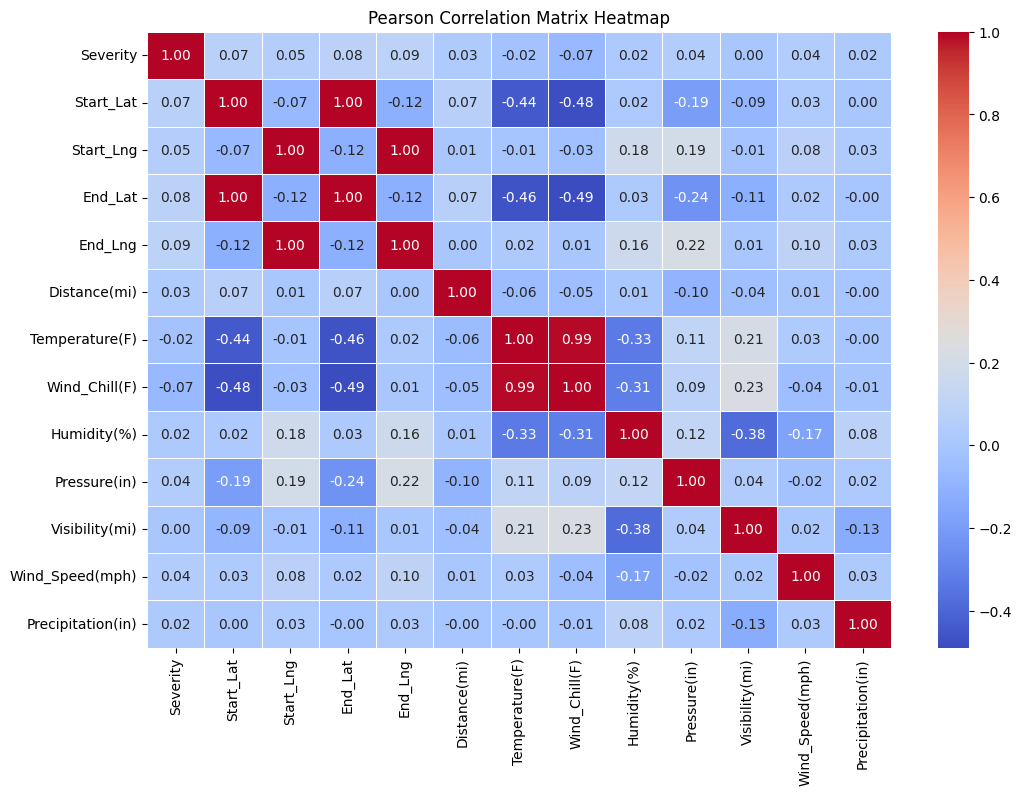

In [ ]:
# 2. Correlation Matrix Heatmap (Pearson Correlation)
plt.figure(figsize=(12, 8))
corr_matrix = df[numeric_cols].corr(method='pearson')
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Pearson Correlation Matrix Heatmap')
plt.show()

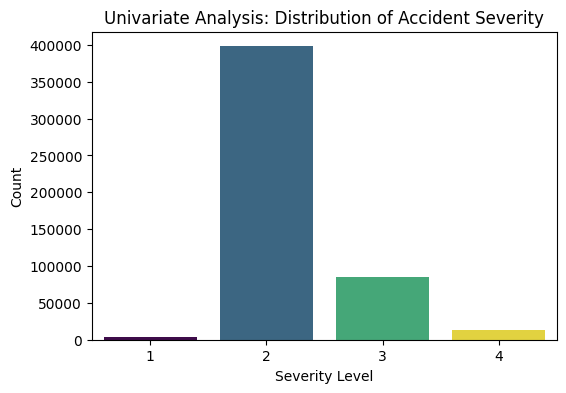

In [ ]:
# Univariate Analysis: Severity Distribution (Categorical/Ordinal)
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Severity', hue='Severity', palette='viridis', legend=False)
plt.title('Univariate Analysis: Distribution of Accident Severity')
plt.xlabel('Severity Level')
plt.ylabel('Count')
plt.show()

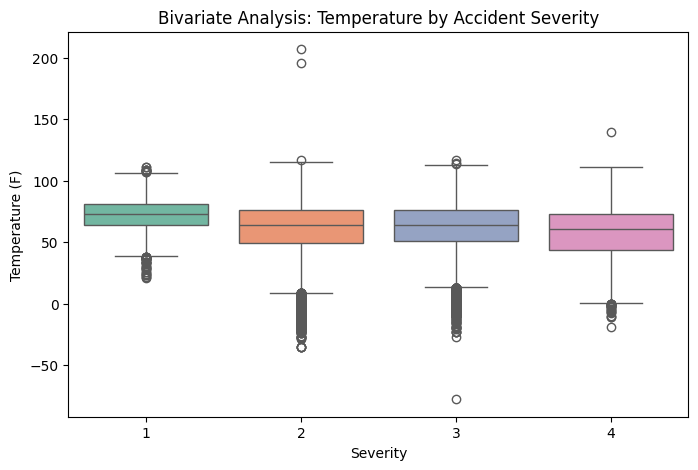

In [ ]:
# Bivariate Analysis: Numerical vs Categorical (Temperature vs Severity)
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Severity', y='Temperature(F)', hue='Severity', palette='Set2', legend=False)
plt.title('Bivariate Analysis: Temperature by Accident Severity')
plt.xlabel('Severity')
plt.ylabel('Temperature (F)')
plt.show()

In [ ]:
import scipy.stats as stats

Text(0.5, 1.0, 'Temperature(F) Distribution Density')

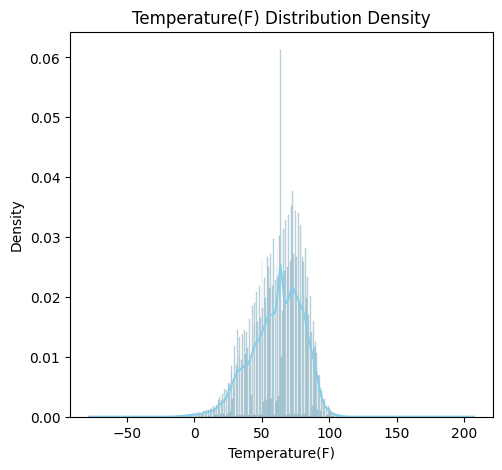

In [ ]:
# Visual Normality Check: Q-Q Plot
plt.figure(figsize=(12, 5))
# KDE plot
plt.subplot(1, 2, 1)
sns.histplot(df['Temperature(F)'], kde=True, color='skyblue', stat='density')
plt.title('Temperature(F) Distribution Density')

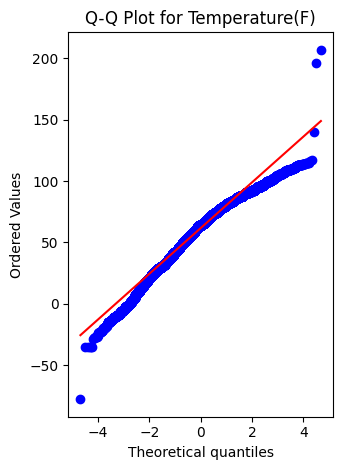

In [ ]:
# Q-Q plot
plt.subplot(1, 2, 2)
stats.probplot(df['Temperature(F)'].dropna(), dist="norm", plot=plt)
plt.title('Q-Q Plot for Temperature(F)')
plt.tight_layout()
plt.show()

In [ ]:
# Prepare data groups
day_temp = df[df['Sunrise_Sunset'] == 'Day']['Temperature(F)'].dropna()
night_temp = df[df['Sunrise_Sunset'] == 'Night']['Temperature(F)'].dropna()

In [ ]:
# Two-Sample Independent t-test (assuming unequal variances)
t_stat, p_val = stats.ttest_ind(day_temp, night_temp, equal_var=False)
print(f"t-statistic: {t_stat:.4f}")
print(f"p-value: {p_val:.4e}")

t-statistic: 230.2820
p-value: 0.0000e+00


In [ ]:
# Evaluate with classic alpha threshold
alpha = 0.05
if p_val < alpha:
    print(f"Reject H0: There is a statistically significant difference in temperature between Day and Night accidents.")
else:
    print("Fail to reject H0: No statistically significant difference in temperature.")

Reject H0: There is a statistically significant difference in temperature between Day and Night accidents.


## Feature Engineering


In [ ]:
# Convert object column to datetime representation to enable extraction properties
df['Start_Time'] = pd.to_datetime(df['Start_Time'], errors='coerce')

# Pull specific numeric representations of chronological components
df['Year'] = df['Start_Time'].dt.year
df['Month'] = df['Start_Time'].dt.month
df['Hour'] = df['Start_Time'].dt.hour
df['Day_of_Week'] = df['Start_Time'].dt.dayofweek # Monday=0, Sunday=6

In [ ]:
# Define numeric edges for grouping hours into distinct period intervals
hour_bins = [-1, 5, 11, 16, 21, 24]
# Match categories corresponding to each mapped numeric bin
hour_labels = ['Late Night', 'Morning', 'Afternoon', 'Evening', 'Night']
df['Time_of_Day'] = pd.cut(df['Hour'], bins=hour_bins, labels=hour_labels)

In [ ]:
# Map nominal categories representing daytime directly to binary indicator features
if 'Sunrise_Sunset' in df.columns:
    df['Is_Day'] = df['Sunrise_Sunset'].map({'Day': 1, 'Night': 0})

In [ ]:
from sklearn.preprocessing import StandardScaler # used to standardize features by removing the mean and scaling the data to a unit variance

scaler = StandardScaler()
# Let's scale Temperature(F) using a reshaped array
if 'Temperature(F)' in df.columns:
    df['Scaled_Temperature'] = scaler.fit_transform(df[['Temperature(F)']])

# Display the newly engineered features
display(df[['Start_Time', 'Year', 'Month', 'Hour', 'Day_of_Week', 'Time_of_Day', 'Is_Day', 'Scaled_Temperature']].head())

,Start_Time,Year,Month,Hour,Day_of_Week,Time_of_Day,Is_Day,Scaled_Temperature
0,2019-06-12 10:10:56,2019.0,6.0,10.0,2.0,Morning,1.0,0.813855
1,NaT,NaN,NaN,NaN,NaN,NaN,0.0,-0.887773
2,NaT,NaN,NaN,NaN,NaN,NaN,1.0,0.335272
3,2022-02-21 17:43:04,2022.0,2.0,17.0,0.0,Evening,1.0,-1.844938
4,2020-12-04 01:46:00,2020.0,12.0,1.0,4.0,Late Night,0.0,-1.047300
